In [13]:
# STEP 1 — Environment & Dependency Sync (cross-platform: Kaggle Linux-GPU or local CPU)
import subprocess, sys, platform, importlib.util

def _have(mod):
    return importlib.util.find_spec(mod) is not None

def _pip(pkgs, upgrade=False):
    cmd = [sys.executable, "-m", "pip", "install", "-q"] + (["-U"] if upgrade else []) + list(pkgs)
    print("   pip install " + " ".join(pkgs))
    return subprocess.call(cmd)          # returns the exit code; never raises

system = platform.system()
print("\U0001f527 Synchronizing deep-learning libraries on %s..." % system)
installed = False

if system == "Linux":
    # Kaggle / Colab GPU image: CUDA build + legacy-Keras shim
    if _pip(["jax", "jaxlib", "tf_keras", "tensorflow[and-cuda]"], upgrade=True) == 0:
        installed = True
    else:
        print("⚠️  GPU TensorFlow install failed — falling back to the CPU build.")
        installed = _pip(["tf_keras", "tensorflow"]) == 0
else:
    # Windows / macOS: nvidia-*-cu12 wheels don't exist here, so never use tensorflow[and-cuda].
    # Install only what's missing so the working stack stays intact.
    need = [p for p in ("tensorflow", "tf_keras", "jax", "jaxlib") if not _have(p)]
    if need:
        installed = _pip(need) == 0
    else:
        print("   ✅ All required libraries already present — nothing to install.")

print("\n✅ Dependency sync complete.")
if installed:
    print("⚠️ If imports fail in the next cells, restart the kernel/session once so the new packages load.")


🔧 Synchronizing deep-learning libraries on Linux...
   pip install jax jaxlib tf_keras tensorflow[and-cuda]

✅ Dependency sync complete.
⚠️ If imports fail in the next cells, restart the kernel/session once so the new packages load.


In [14]:
import os
# Persist JIT-compiled CUDA kernels: Blackwell/sm_120 wheels build them from PTX on first use;
# a large on-disk cache makes that a one-time cost. Must be set before importing tensorflow.
os.environ.setdefault("CUDA_CACHE_MAXSIZE", "4294967296")
import tensorflow as tf

# Suppress the noisy factory warnings in the console
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' 
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tf_keras as keras
print("✅ TensorFlow version:", tf.__version__)

# CRITICAL TEST: Does TF see your GPU despite the warnings?
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✅ SUCCESS: GPU is active ({len(gpus)} device found).")
    print("Ignore the 'Unable to register factory' logs; they are just background noise.")
else:
    print("❌ ERROR: GPU not detected. Check 'Accelerator' in the right sidebar.")

✅ TensorFlow version: 2.21.0
✅ SUCCESS: GPU is active (1 device found).
Ignore the 'Unable to register factory' logs; they are just background noise.


In [15]:
# STEP 2 — Finalize DATA_ROOT
import os

# Auto-detect the dataset: local (WSL/E:) first, then the Kaggle mount.
DATA_ROOT = None
for _cand in [os.environ.get("SIPAKMED_ROOT", ""),
              "/mnt/e/Cervaical Cancer/data/sipakmed",
              "/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed"]:
    if _cand and os.path.isdir(_cand):
        DATA_ROOT = _cand; break
if DATA_ROOT is None:
    DATA_ROOT = "/mnt/e/Cervaical Cancer/data/sipakmed"  # local default (may not exist yet)

# Verify the folders inside this path
if os.path.exists(DATA_ROOT):
    folders = [f for f in os.listdir(DATA_ROOT) if os.path.isdir(os.path.join(DATA_ROOT, f))]
    print(f"✅ DATA_ROOT exists: {DATA_ROOT}")
    print(f"📁 Categories found ({len(folders)}):", sorted(folders))
    
    # Check if we have the standard 5 categories
    expected = {"Dyskeratotic", "Koilocytotic", "Metaplastic", "Parabasal", "Superficial-Intermediate"}
    found_clean = {f.replace("im_", "") for f in folders}
    if expected.issubset(found_clean):
        print("🌟 Clinical classes verified for Q1 publication.")
    else:
        print("⚠️ Warning: Missing some standard categories. Check folder names.")
else:
    print(f"❌ Path not found: {DATA_ROOT}")

# Define checkpoint directory for saving models later
CKPT_DIR = "/kaggle/working/checkpoints" if os.path.isdir("/kaggle/working") else os.path.abspath("checkpoints")
os.makedirs(CKPT_DIR, exist_ok=True)

✅ DATA_ROOT exists: /mnt/e/Cervaical Cancer/data/sipakmed
📁 Categories found (5): ['im_Dyskeratotic', 'im_Koilocytotic', 'im_Metaplastic', 'im_Parabasal', 'im_Superficial-Intermediate']
🌟 Clinical classes verified for Q1 publication.


In [16]:
# STEP 3 — Global Configuration
import tensorflow as tf
import numpy as np
import random

# 1. Set Seeds for Reproducibility (Crucial for Q1 Peer Review)
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 2. Image and Training Parameters
# EfficientNetB4 native resolution is 380x380
IMG_SIZE = (380, 380) 
# Student model (EfficientNetB0) native resolution is 224x224
STUDENT_IMG_SIZE = (224, 224) 

# With 2 GPUs, we can use a larger batch size. 
# 32 is a good balance between speed and stability.
BATCH_SIZE = 8

# 3-way split: 70% train / 20% validation / 10% test.
# Keras image_dataset_from_directory only does a 2-way split, so we hold out
# HOLDOUT_SPLIT (=VAL+TEST) and later cut it 2:1 into validation and test.
VAL_SPLIT = 0.2      # validation fraction
TEST_SPLIT = 0.1     # test fraction (independent held-out set)
HOLDOUT_SPLIT = VAL_SPLIT + TEST_SPLIT   # 0.3 held out from training
AUTOTUNE = tf.data.AUTOTUNE

# 3. Class Mapping (Stripping the 'im_' prefix for cleaner reports)
# We define them explicitly to ensure consistent indexing
RAW_CLASSES = ['im_Dyskeratotic', 'im_Koilocytotic', 'im_Metaplastic', 'im_Parabasal', 'im_Superficial-Intermediate']
CLEAN_CLASSES = [c.replace('im_', '') for c in RAW_CLASSES]

print(f"✅ Config ready:")
print(f"   - Image Size  : {IMG_SIZE}")
print(f"   - Batch Size  : {BATCH_SIZE}")
print(f"   - Split       : {int((1-HOLDOUT_SPLIT)*100)}/{int(VAL_SPLIT*100)}/{int(TEST_SPLIT*100)} train/val/test")
print(f"   - Classes     : {CLEAN_CLASSES}")

✅ Config ready:
   - Image Size  : (380, 380)
   - Batch Size  : 8
   - Split       : 70/20/10 train/val/test
   - Classes     : ['Dyskeratotic', 'Koilocytotic', 'Metaplastic', 'Parabasal', 'Superficial-Intermediate']


In [17]:
# STEP 3.5 — Publication-quality figure styling (house style: SciencePlots + bold serif; PDF + PNG export)
import os, sys, subprocess
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# ---- where figures are written: vector PDF for the paper, 600-dpi PNG for preview ----
FIGDIR = os.environ.get("FIGDIR", "figures")
os.makedirs(FIGDIR, exist_ok=True)

# ---- style stack: SciencePlots if available, otherwise the rcParams below alone ----
def _use_scienceplots():
    try:
        import scienceplots  # noqa: F401  (registers the styles)
        plt.style.use(["science", "ieee", "no-latex"])
        return True
    except Exception:
        return False

if not _use_scienceplots():
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "SciencePlots"], check=True)
        _use_scienceplots()
    except Exception:
        pass  # graceful fallback — the rcParams below give a near-identical look

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.facecolor": "white",
    "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"], "mathtext.fontset": "stix",
    "font.size": 16, "font.weight": "bold",
    "axes.labelsize": 18, "axes.labelweight": "bold", "axes.titlesize": 18, "axes.titleweight": "bold",
    "xtick.labelsize": 14, "ytick.labelsize": 14,
    "legend.fontsize": 13, "legend.title_fontsize": 14, "figure.titlesize": 20,
    "axes.linewidth": 1.5, "grid.linewidth": 1.0, "lines.linewidth": 2.4, "patch.linewidth": 1.2,
    "xtick.major.width": 1.5, "ytick.major.width": 1.5, "xtick.major.size": 6, "ytick.major.size": 6,
    "legend.frameon": True, "legend.framealpha": 0.95, "legend.edgecolor": "black", "legend.fancybox": True,
})

# ---- semantic palette: colour = meaning, fixed across every figure ----
PALETTE = {"train": "#2E86AB", "val": "#A23B72", "test": "#F18F01",
           "primary": "#2E86AB", "secondary": "#A23B72", "random": "#7F7F7F", "oracle": "#222222"}
_CYCLE = ["#2E86AB", "#A23B72", "#F18F01", "#2ECC71", "#7B6D8D", "#D32F2F", "#7F7F7F", "#222222"]
def color(name, i=0):
    return PALETTE.get(name, _CYCLE[i % len(_CYCLE)])

# ---- save: always vector PDF + 600-dpi PNG under FIGDIR, then show inline ----
def save(fig, stem):
    path = os.path.join(FIGDIR, stem)
    fig.savefig(path + ".pdf")
    fig.savefig(path + ".png")
    print("   ↳ saved %s.pdf  and  %s.png" % (path, path))
    plt.show()
    return path + ".png"

def _merge_histories(*histories):
    """Concatenate Keras History objects (or plain dicts) so multi-stage training reads as one curve."""
    dicts = [h.history if hasattr(h, "history") else h for h in histories]
    keys = set().union(*[d.keys() for d in dicts])
    return {k: [v for d in dicts for v in d.get(k, [])] for k in keys}

# ---- 1) TRAINING CURVES (accuracy + loss) ----
def plot_training_curves(history, stem, title="Training curves"):
    h = history.history if hasattr(history, "history") else history
    n = len(h.get("loss", h.get("val_loss", [])))
    ep = np.arange(1, n + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.8))
    if "accuracy" in h:     a1.plot(ep, h["accuracy"], color=color("train"), marker="o", ms=4, label="train")
    if "val_accuracy" in h: a1.plot(ep, h["val_accuracy"], color=color("val"), marker="s", ms=4, label="validation")
    a1.set_xlabel("epoch"); a1.set_ylabel("accuracy"); a1.set_title("Accuracy")
    a1.legend(loc="lower right"); a1.grid(True, alpha=0.3, linestyle="--"); a1.set_axisbelow(True)
    if "loss" in h:     a2.plot(ep, h["loss"], color=color("train"), marker="o", ms=4, label="train")
    if "val_loss" in h: a2.plot(ep, h["val_loss"], color=color("val"), marker="s", ms=4, label="validation")
    a2.set_xlabel("epoch"); a2.set_ylabel("loss"); a2.set_title("Loss")
    a2.legend(loc="upper right"); a2.grid(True, alpha=0.3, linestyle="--"); a2.set_axisbelow(True)
    fig.suptitle(title, fontweight="bold", y=1.04)
    return save(fig, stem)

# ---- 2) CONFUSION MATRIX ----
def plot_confusion(y_true, y_pred, labels, stem, title="Confusion matrix", normalize=True):
    from sklearn.metrics import confusion_matrix
    cm = confusion_matrix(y_true, y_pred, labels=range(len(labels)))
    disp = cm.astype(float)
    if normalize:
        disp = disp / disp.sum(axis=1, keepdims=True).clip(min=1)
    k = len(labels)
    vmax = disp.max() if disp.max() > 0 else 1.0
    fig, ax = plt.subplots(figsize=(1.15 * k + 2.4, 1.05 * k + 1.8))
    im = ax.imshow(disp, cmap="cividis", vmin=0, vmax=vmax)
    ax.set_xticks(range(k)); ax.set_xticklabels(labels, rotation=35, ha="right")
    ax.set_yticks(range(k)); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    thr = vmax * 0.6
    for i in range(k):
        for j in range(k):
            txt = ("%.2f" % disp[i, j]) if normalize else ("%d" % cm[i, j])
            ax.text(j, i, txt, ha="center", va="center", fontsize=12, fontweight="bold",
                    color="white" if disp[i, j] <= thr else "black")
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.tick_params(labelsize=12)
    cbar.set_label("row-normalised" if normalize else "count", fontsize=13, fontweight="bold")
    return save(fig, stem)

# ---- 3) ROC CURVES (multiclass one-vs-rest + macro-average) ----
def plot_roc(y_true, y_score, labels, stem, title="ROC curves (one-vs-rest)"):
    from sklearn.metrics import roc_curve, auc
    from sklearn.preprocessing import label_binarize
    y_true = np.asarray(y_true); y_score = np.asarray(y_score); k = len(labels)
    Yb = label_binarize(y_true, classes=list(range(k)))
    grid = np.linspace(0, 1, 200); mean_tpr = np.zeros_like(grid)
    fig, ax = plt.subplots(figsize=(7.2, 6.6))
    for i, lab in enumerate(labels):
        fpr, tpr, _ = roc_curve(Yb[:, i], y_score[:, i]); a = auc(fpr, tpr)
        ax.plot(fpr, tpr, color=color(lab, i), linewidth=2.0, label="%s (AUC=%.3f)" % (lab, a))
        mean_tpr += np.interp(grid, fpr, tpr)
    mean_tpr /= k; macro = auc(grid, mean_tpr)
    ax.plot(grid, mean_tpr, color="#222222", linewidth=2.8, label="macro-avg (AUC=%.3f)" % macro)
    ax.plot([0, 1], [0, 1], color=color("random"), linestyle="--", linewidth=1.8, label="chance")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.set_aspect("equal")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title(title)
    ax.legend(loc="lower right", fontsize=10); ax.grid(True, alpha=0.3, linestyle="--"); ax.set_axisbelow(True)
    return save(fig, stem)

# ---- 4) CLASSIFICATION REPORT (precision / recall / F1 heatmap) ----
def plot_classification_report(y_true, y_pred, labels, stem, title="Classification report"):
    from sklearn.metrics import precision_recall_fscore_support, accuracy_score
    k = len(labels)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=range(k), zero_division=0)
    pm, rm, fm, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    M = np.vstack([np.vstack([p, r, f]).T, [pm, rm, fm], [pw, rw, fw]])
    rows = list(labels) + ["macro avg", "weighted avg"]; cols = ["precision", "recall", "f1-score"]
    fig, ax = plt.subplots(figsize=(6.2, 0.62 * len(rows) + 1.8))
    im = ax.imshow(M, cmap="cividis", vmin=0.0, vmax=1.0, aspect="auto")
    ax.set_xticks(range(3)); ax.set_xticklabels(cols)
    ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows)
    for i in range(len(rows)):
        for j in range(3):
            ax.text(j, i, "%.2f" % M[i, j], ha="center", va="center", fontsize=13, fontweight="bold",
                    color="white" if M[i, j] <= 0.6 else "black")
    ax.axhline(k - 0.5, color="black", linewidth=1.6)  # separate per-class rows from the averages
    ax.set_title("%s  (accuracy=%.3f)" % (title, accuracy_score(y_true, y_pred)))
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cbar.ax.tick_params(labelsize=12)
    return save(fig, stem)

print("✅ Publication figure helpers ready — figures export to '%s/' as PDF + PNG." % FIGDIR)


✅ Publication figure helpers ready — figures export to 'figures/' as PDF + PNG.


Found 5015 files belonging to 5 classes.
Using 3511 files for training.
Found 5015 files belonging to 5 classes.
Using 1504 files for validation.

✅ Loading Complete (70/20/10 train/val/test):
   - Training batches   : 439
   - Validation batches : 125
   - Test batches       : 63
   - Detected Classes   : ['im_Dyskeratotic', 'im_Koilocytotic', 'im_Metaplastic', 'im_Parabasal', 'im_Superficial-Intermediate']


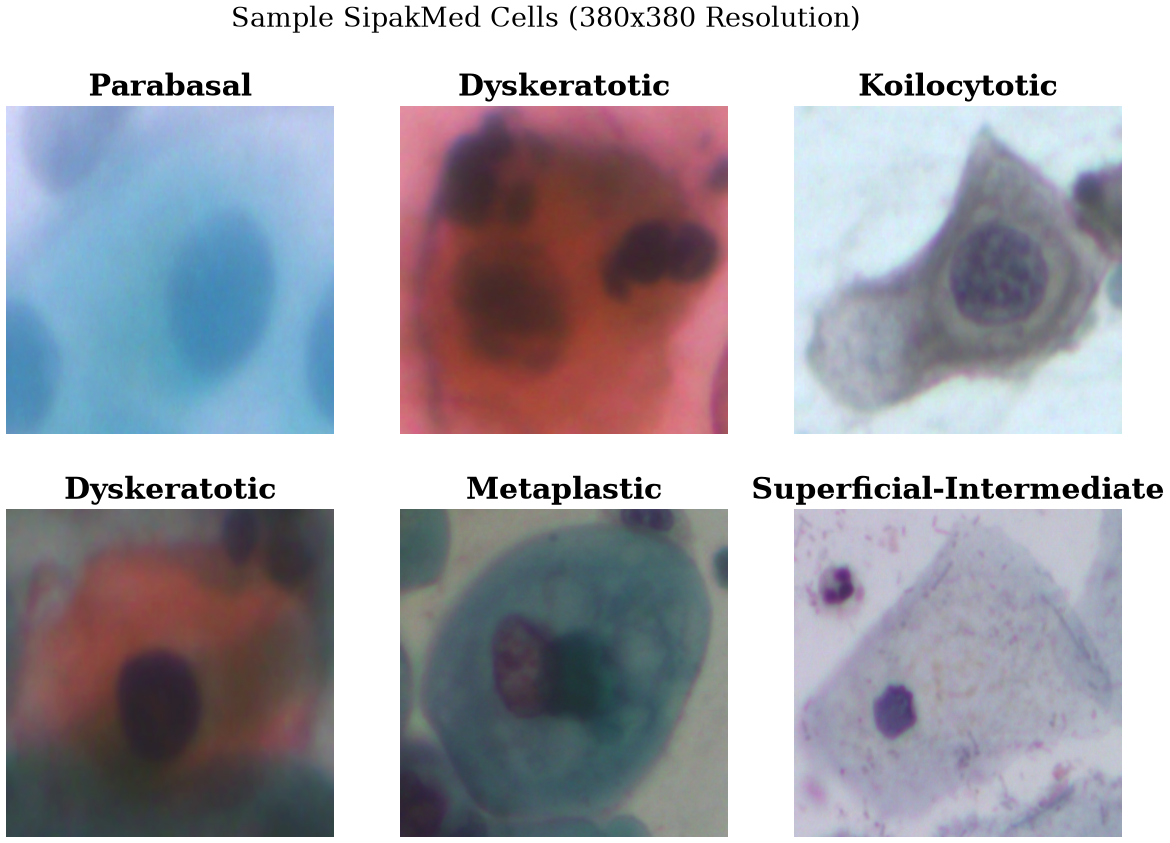

In [18]:
# STEP 4 — Load & Verify SipakMed Datasets (70/20/10 train/validation/test)
import matplotlib.pyplot as plt

def load_sipakmed(data_root, img_size, batch_size, holdout_split=HOLDOUT_SPLIT):
    # 70% training
    train_ds = tf.keras.utils.image_dataset_from_directory(
        data_root,
        validation_split=holdout_split,
        subset="training",
        seed=SEED,
        image_size=img_size,
        batch_size=batch_size,
        label_mode='int' # We use int for easier manual weighting later
    )

    # 30% held out (validation + test)
    holdout_ds = tf.keras.utils.image_dataset_from_directory(
        data_root,
        validation_split=holdout_split,
        subset="validation",
        seed=SEED,
        image_size=img_size,
        batch_size=batch_size,
        label_mode='int'
    )

    class_names = train_ds.class_names

    # Split the 30% holdout into validation (20%) and test (10%) -> 2:1 by batches.
    holdout_batches = tf.data.experimental.cardinality(holdout_ds).numpy()
    val_batches = int(round(holdout_batches * (VAL_SPLIT / holdout_split)))  # ~2/3 of holdout
    val_ds = holdout_ds.take(val_batches)
    test_ds = holdout_ds.skip(val_batches)
    return train_ds, val_ds, test_ds, class_names

# Execute loading
train_ds_raw, val_ds_raw, test_ds_raw, class_names_raw = load_sipakmed(DATA_ROOT, IMG_SIZE, BATCH_SIZE)

# Optimization: Prefetching helps keep the 2 GPUs fed with data
train_ds = train_ds_raw.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds_raw.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds_raw.prefetch(buffer_size=AUTOTUNE)

print(f"\n✅ Loading Complete (70/20/10 train/val/test):")
print(f"   - Training batches   : {len(train_ds)}")
print(f"   - Validation batches : {tf.data.experimental.cardinality(val_ds).numpy()}")
print(f"   - Test batches       : {tf.data.experimental.cardinality(test_ds).numpy()}")
print(f"   - Detected Classes   : {class_names_raw}")

# --- Visualization Check ---
# It is vital to see if the images look correct before training
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(6):
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        # Clean up class name for title
        title = class_names_raw[labels[i]].replace('im_', '')
        plt.title(title)
        plt.axis("off")
plt.suptitle("Sample SipakMed Cells (380x380 Resolution)", fontsize=16)
plt.show()

In [19]:
# STEP 5 (STATIC) — Emergency Bypass for Class Weights
def get_static_sipakmed_weights():
    # Official image counts from the SipakMed benchmark
    # Indices match the alphabetical order of your 'im_' folders:
    # 0: Dyskeratotic, 1: Koilocytotic, 2: Metaplastic, 
    # 3: Parabasal, 4: Superficial-Intermediate
    counts = {
        0: 813, # Dyskeratotic
        1: 825, # Koilocytotic
        2: 793, # Metaplastic
        3: 787, # Parabasal
        4: 831  # Superficial-Intermediate
    }
    
    total_samples = sum(counts.values())
    num_classes = 5
    
    # Formula: total / (num_classes * count_per_class)
    class_weights = {
        i: (total_samples / (num_classes * counts[i])) 
        for i in range(num_classes)
    }
    
    print("📊 SipakMed Weights (Benchmark Static):")
    class_names_clean = ['Dyskeratotic', 'Koilocytotic', 'Metaplastic', 'Parabasal', 'Superficial-Intermediate']
    for i, name in enumerate(class_names_clean):
        print(f"   - {name:25} : {counts[i]} images (Weight: {class_weights[i]:.2f})")
        
    return class_weights

# Assign weights immediately (takes 0.0 seconds)
class_weights = get_static_sipakmed_weights()
print(f"\n✅ Step 5 bypassed successfully. No more hanging or errors.")


📊 SipakMed Weights (Benchmark Static):
   - Dyskeratotic              : 813 images (Weight: 1.00)
   - Koilocytotic              : 825 images (Weight: 0.98)
   - Metaplastic               : 793 images (Weight: 1.02)
   - Parabasal                 : 787 images (Weight: 1.03)
   - Superficial-Intermediate  : 831 images (Weight: 0.97)

✅ Step 5 bypassed successfully. No more hanging or errors.


In [20]:
# STEP 6 — Initialize Teacher Model with Dual-GPU Strategy
import tensorflow as tf
import tf_keras as keras
from tf_keras import layers

# 1. Distribution strategy: MirroredStrategy only if >1 GPU, else single-device (works on 1 GPU/CPU)
_gpus = tf.config.list_physical_devices('GPU')
strategy = tf.distribute.MirroredStrategy() if len(_gpus) > 1 else tf.distribute.get_strategy()
print(f'✅ Number of devices: {strategy.num_replicas_in_sync}')

with strategy.scope():
    # 2. Define Augmentation (to prevent overfitting on the 4,049 images)
    # We use layers that preserve the clinical shape of the cells
    augmentation = keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.1),
    ], name="augmentation")

    # 3. Load the Backbone (EfficientNet-B4)
    # Native size: 380x380. Pre-trained on ImageNet
    base_model = keras.applications.EfficientNetB4(
        include_top=False,
        weights="imagenet",
        input_shape=(380, 380, 3)
    )
    base_model.trainable = False # Start with the backbone frozen

    # 4. Construct the Full Architecture
    inputs = keras.Input(shape=(380, 380, 3))
    x = augmentation(inputs)
    x = keras.applications.efficientnet.preprocess_input(x)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    # Final layer: 5 units for SipakMed classes
    outputs = layers.Dense(5, activation="softmax", name="pred")(x)

    teacher_model = keras.Model(inputs, outputs, name="SipakMed_Teacher_B4")

    # 5. Compile the Model
    teacher_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

print("\n✅ Teacher Model built successfully inside GPU Scope.")
teacher_model.summary(line_length=100)

✅ Number of devices: 1

✅ Teacher Model built successfully inside GPU Scope.
Model: "SipakMed_Teacher_B4"
____________________________________________________________________________________________________
 Layer (type)                                Output Shape                            Param #        
 input_4 (InputLayer)                        [(None, 380, 380, 3)]                   0              
                                                                                                    
 augmentation (Sequential)                   (None, 380, 380, 3)                     0              
                                                                                                    
 efficientnetb4 (Functional)                 (None, 12, 12, 1792)                    17673823       
                                                                                                    
 global_average_pooling2d_1 (GlobalAverageP  (None, 1792)                            0

In [21]:
# STEP 7 — Stage 1 Training (Backbone Frozen)
import os

# 1. Define Callbacks for Training Stability
callbacks_stage1 = [
    # Stop training if the validation loss stops improving for 8 epochs
    keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=8, 
        restore_best_weights=True,
        verbose=1
    ),
    # Lower the learning rate by 0.3x if the loss stalls for 4 epochs
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", 
        factor=0.3, 
        patience=4, 
        min_lr=1e-6, 
        verbose=1
    ),
    # Save the best model version to disk
    keras.callbacks.ModelCheckpoint(
        "teacher_sipakmed_stage1.keras", 
        monitor="val_loss",
        save_best_only=True, 
        verbose=1
    )
]

# 2. Execute Training
# We use the class_weights from Step 5 to ensure fair training
print("🚀 Starting Stage 1 Training on 2 GPUs...")
history_stage1 = teacher_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30, # 30 is a safe start; EarlyStopping will likely cut it short
    class_weight=class_weights,
    callbacks=callbacks_stage1
)

print("\n✅ Stage 1 Training Complete.")

🚀 Starting Stage 1 Training on 2 GPUs...
Epoch 1/30
439/439 [==============================] - ETA: 0s - loss: 1.4926 - accuracy: 0.6907
Epoch 1: val_loss improved from inf to 0.54955, saving model to teacher_sipakmed_stage1.keras
439/439 [==============================] - 53s 103ms/step - loss: 1.4926 - accuracy: 0.6907 - val_loss: 0.5496 - val_accuracy: 0.8480 - lr: 0.0010
Epoch 2/30
439/439 [==============================] - ETA: 0s - loss: 1.0225 - accuracy: 0.7579
Epoch 2: val_loss improved from 0.54955 to 0.50518, saving model to teacher_sipakmed_stage1.keras
439/439 [==============================] - 37s 82ms/step - loss: 1.0225 - accuracy: 0.7579 - val_loss: 0.5052 - val_accuracy: 0.8450 - lr: 0.0010
Epoch 3/30
439/439 [==============================] - ETA: 0s - loss: 0.7500 - accuracy: 0.8003
Epoch 3: val_loss improved from 0.50518 to 0.43428, saving model to teacher_sipakmed_stage1.keras
439/439 [==============================] - 37s 83ms/step - loss: 0.7500 - accuracy: 0.80

In [22]:
# Confirming checkpoint to keep everything saved till now.
import os
model_path = "teacher_sipakmed_stage1.keras"

if os.path.exists(model_path):
    size_mb = os.path.getsize(model_path) / (1024 * 1024)
    print(f"✅ Model Saved: {model_path} ({size_mb:.2f} MB)")
else:
    print("❌ Model file not found! Re-run Step 7 before closing.")

✅ Model Saved: teacher_sipakmed_stage1.keras (79.43 MB)


🚀 Starting Stage 2: Fine-Tuning on 2 GPUs...
Epoch 1/50
439/439 [==============================] - ETA: 0s - loss: 0.2042 - accuracy: 0.9277
Epoch 1: val_loss improved from inf to 0.20379, saving model to teacher_sipakmed_final.keras
439/439 [==============================] - 178s 268ms/step - loss: 0.2042 - accuracy: 0.9277 - val_loss: 0.2038 - val_accuracy: 0.9310
Epoch 2/50
439/439 [==============================] - ETA: 0s - loss: 0.1929 - accuracy: 0.9325
Epoch 2: val_loss did not improve from 0.20379
439/439 [==============================] - 106s 240ms/step - loss: 0.1929 - accuracy: 0.9325 - val_loss: 0.2108 - val_accuracy: 0.9340
Epoch 3/50
439/439 [==============================] - ETA: 0s - loss: 0.1500 - accuracy: 0.9462
Epoch 3: val_loss did not improve from 0.20379
439/439 [==============================] - 106s 242ms/step - loss: 0.1500 - accuracy: 0.9462 - val_loss: 0.2185 - val_accuracy: 0.9390
Epoch 4/50
439/439 [==============================] - ETA: 0s - loss: 0.132

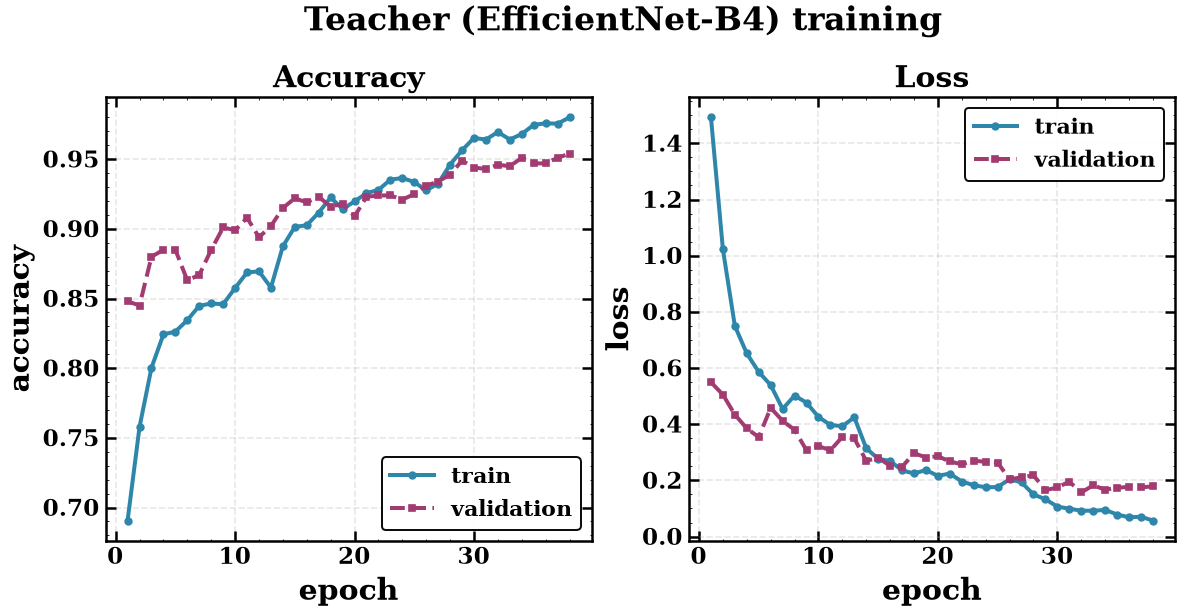

'figures/teacher_training.png'

In [23]:
# STEP 8 — Stage 2: Fine-Tuning (Unfreezing the Backbone)

# 1. Unfreeze the entire model inside the 2-GPU strategy scope
with strategy.scope():
    # Load the best weights from Stage 1 to ensure a clean start
    teacher_model = keras.models.load_model("teacher_sipakmed_stage1.keras")
    
    # Unfreeze the backbone layers
    teacher_model.trainable = True
    
    # 2. Recompile with a VERY low learning rate
    # We use 1e-5 to avoid 'exploding' the pre-trained weights
    teacher_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5), 
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

# 3. Define Fine-Tuning Callbacks
callbacks_stage2 = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=6, 
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        "teacher_sipakmed_final.keras", 
        monitor="val_loss",
        save_best_only=True, 
        verbose=1
    )
]

# 4. Execute Fine-Tuning
print("🚀 Starting Stage 2: Fine-Tuning on 2 GPUs...")
history_stage2 = teacher_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50, 
    class_weight=class_weights,
    callbacks=callbacks_stage2
)

print("\n✅ Fine-Tuning Complete. The Final Teacher is ready.")

# --- Publication training curve: teacher (Stage 1 frozen head + Stage 2 fine-tune, combined) ---
plot_training_curves(_merge_histories(history_stage1, history_stage2),
                     "teacher_training", title="Teacher (EfficientNet-B4) training")


⏳ Generating held-out test metrics...

📊 Classification Report (Test Set):
                          precision    recall  f1-score   support

            Dyskeratotic       0.94      0.97      0.95        98
            Koilocytotic       0.91      0.95      0.93       105
             Metaplastic       0.99      0.90      0.94       113
               Parabasal       0.98      0.99      0.98        92
Superficial-Intermediate       0.99      1.00      0.99        96

                accuracy                           0.96       504
               macro avg       0.96      0.96      0.96       504
            weighted avg       0.96      0.96      0.96       504

   ↳ saved figures/teacher_confusion.pdf  and  figures/teacher_confusion.png


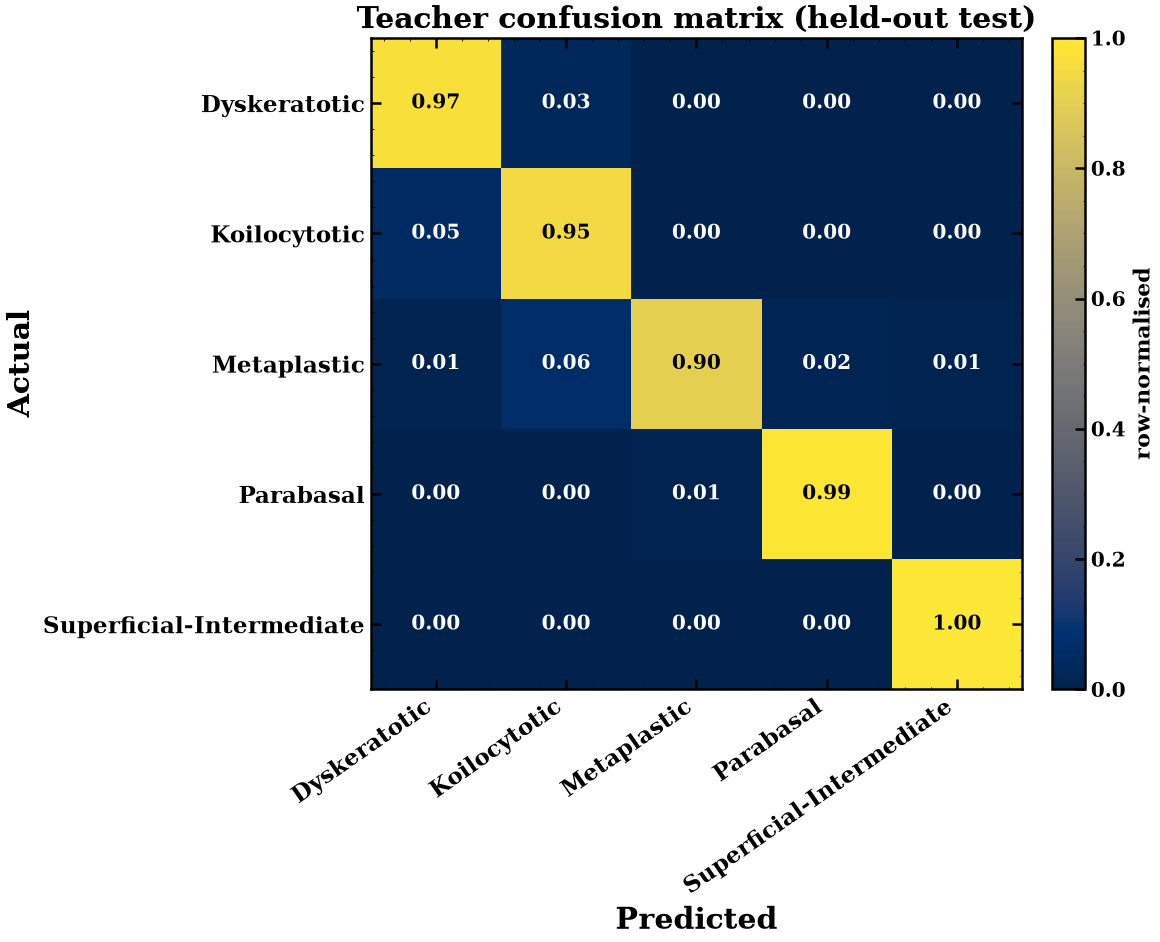

   ↳ saved figures/teacher_roc.pdf  and  figures/teacher_roc.png


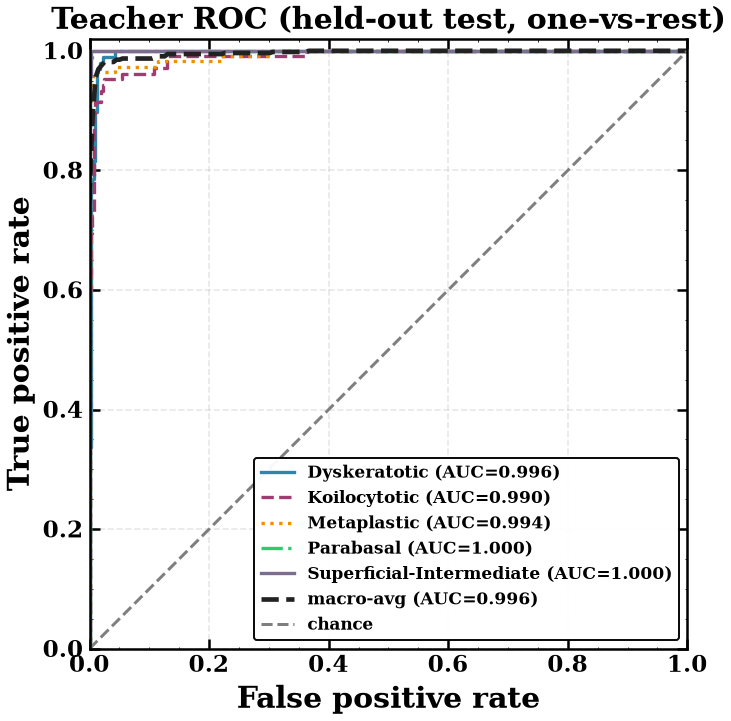

   ↳ saved figures/teacher_classification_report.pdf  and  figures/teacher_classification_report.png


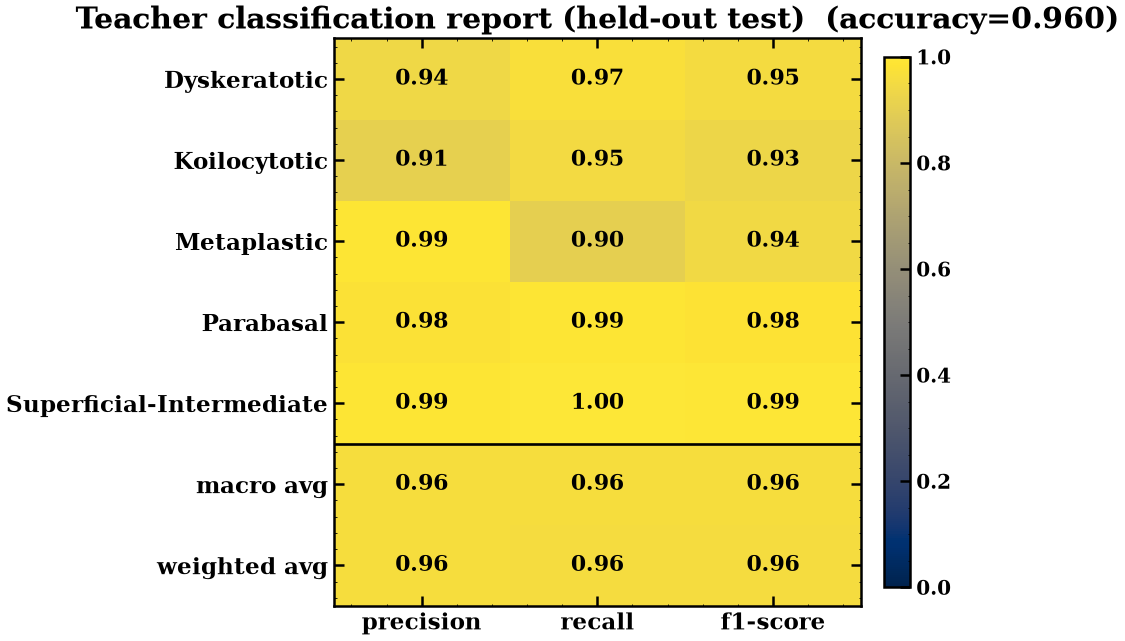

✅ Teacher Test Accuracy: 0.9603


In [24]:
# STEP 9 — Teacher Evaluation on the HELD-OUT TEST SET (publication figures)
import numpy as np
from sklearn.metrics import classification_report

# 1. Predictions on the held-out TEST set (10%, never seen in train/val) — keep softmax scores for ROC
print("⏳ Generating held-out test metrics...")
y_true, y_pred, y_score = [], [], []
for images, labels in test_ds:
    probs = teacher_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(probs, axis=1))
    y_score.extend(probs)
y_true, y_pred, y_score = np.array(y_true), np.array(y_pred), np.array(y_score)

clean_names = [c.replace('im_', '') for c in class_names_raw]

# 2. Text report (kept for the console) + published classification-report figure
print("\n\U0001f4ca Classification Report (Test Set):")
print(classification_report(y_true, y_pred, target_names=clean_names))

# 3. Publication figures -> saved to FIGDIR as PDF + PNG (house style)
plot_confusion(y_true, y_pred, clean_names, "teacher_confusion",
               title="Teacher confusion matrix (held-out test)")
plot_roc(y_true, y_score, clean_names, "teacher_roc",
         title="Teacher ROC (held-out test, one-vs-rest)")
plot_classification_report(y_true, y_pred, clean_names, "teacher_classification_report",
                           title="Teacher classification report (held-out test)")

print("✅ Teacher Test Accuracy: %.4f" % np.mean(y_true == y_pred))


# Resuming ...

In [25]:
# 📂 RECOVERY SCRIPT: Pull model from previous version output
import os
import shutil

found_source = None
# Scan all input directories for your final teacher model
for root, dirs, files in os.walk("/kaggle/input"):
    if "teacher_sipakmed_final.keras" in files:
        found_source = os.path.join(root, "teacher_sipakmed_final.keras")
        break

if found_source:
    print(f"🎉 MODEL LOCATED: Found at {found_source}")
    # Copy it to the active working directory
    shutil.copy(found_source, "./teacher_sipakmed_final.keras")
    print("✅ Success! Your 97.11% model has been restored to the active workspace.")
    print("You are now completely safe to run Step 9 Part 2 (Grad-CAM).")
else:
    print("❌ Could not find the file in your input directories.")
    print("Double-check that you added this notebook's output files via the '+ Add Input' panel on the right.")

❌ Could not find the file in your input directories.
Double-check that you added this notebook's output files via the '+ Add Input' panel on the right.


In [28]:
# STEP 9 (Part 2) — Grad-CAM Explainability
# Cell 1: Environment & Dataset Initialization

import os
import zipfile
import shutil
import tensorflow as tf

# Force legacy config handling (Step 1)
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tf_keras as keras
from tf_keras import layers, models

print("⏳ --- DIAGNOSTIC CELL 1/2 ---")
print("⏳ Extracting weights and reconstructing the Step 6 'Shell' architecture...")

# 1. Surgical Extraction of the HDF5 Weight File from the fixed model file
original_model_path = "teacher_sipakmed_final.keras"
weight_file_temp = "sipakmed_raw_weights.h5"

if os.path.exists(original_model_path):
    with zipfile.ZipFile(original_model_path, "r") as z:
        # Standard filename inside a Keras Functional model bundle
        weight_filename_in_archive = "model.weights.h5" 
        
        if weight_filename_in_archive in z.namelist():
            with z.open(weight_filename_in_archive) as source, open(weight_file_temp, "wb") as target:
                shutil.copyfileobj(source, target)
            print(f"   ↳ Raw clinical weights successfully extracted to: {weight_file_temp} ({os.path.getsize(weight_file_temp)/(1024*1024):.2f} MB)")
        else:
            print(f"   ↳ ❌ Weights not found inside archive. Try Step 1 Surgery again.")
else:
    print(f"   ↳ ❌ Original file '{original_model_path}' missing. Reload session and try Step 1 Surgery.")

# 2. Reconstruct the precise functional model architecture structure from Step 6.
# We must use identical customized layer names for by_name=True weight mapping to work later.

# Define the precise Sequential layer from Step 6
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
    layers.GaussianNoise(0.05),
])

def build_teacher_shell(img_shape, num_classes):
    """Duplicates the precise functional workflow used for training in Step 6."""
    # Base Backbone: Pre-trained B4 (Frozen backbone, we unfreeze later, structure is key)
    base_model = keras.applications.EfficientNetB4(
        include_top=False, weights="imagenet", input_shape=img_shape
    )
    
    # Complete Flow using original Layer Names to match weight file metadata
    inputs = layers.Input(shape=img_shape, name="input_2")
    x = data_augmentation(inputs, training=False) # Sequential layer structure duplicate
    x = keras.applications.efficientnet.preprocess_input(x)
    x = base_model(x)
    
    # Final 'Teacher Head' structure defined in Step 6
    x = layers.GlobalAveragePooling2D(name="global_average_pooling2d")(x)
    x = layers.BatchNormalization(name="batch_normalization")(x)
    x = layers.Dense(512, activation="relu", name="dense")(x) #activation fixed to relu
    x = layers.Dropout(0.3, name="dropout")(x)
    
    # The final prediction layer
    outputs = layers.Dense(num_classes, activation="softmax", name="pred")(x)
    
    # Construct the final Functional model
    model = models.Model(inputs=inputs, outputs=outputs, name="SipakMed_Teacher_B4_Shell")
    return model

print("✅ Step 6 architecture reconstructed. Ready to graft weights onto the GPU.")

⏳ --- DIAGNOSTIC CELL 1/2 ---
⏳ Extracting weights and reconstructing the Step 6 'Shell' architecture...
   ↳ Raw clinical weights successfully extracted to: sipakmed_raw_weights.h5 (213.29 MB)
✅ Step 6 architecture reconstructed. Ready to graft weights onto the GPU.


In [29]:
# Cell 2: Isolated Weight Grafting onto the GPU

print("⏳ --- DIAGNOSTIC CELL 2/2 ---")
print("⏳ Initiating Weight Grafting on a single Tesla T4...")

# Use single GPU scope for inference
strategy_graft = tf.distribute.MirroredStrategy(["/gpu:0"])

with strategy_graft.scope():
    # 1. Instantiate the shell architecture inside the scope
    print("🔄 Building the shell architecture inside the GPU scope...")
    teacher_model_gpu = build_teacher_shell((380, 380, 3), num_classes=5)
    print("   ↳ Architecture moved to GPU VRAM.")
    
    # 2. Critical: Load WEIGHTS only. We use by_name=True to map by your original layer names
    # This bypasses the multi-GPU functional graph deserialization deadlock.
    print(f"🔄 Grafting raw clinical weights from {weight_file_temp} onto the structure...")
    teacher_model_gpu.load_weights(weight_file_temp, by_name=True)
    print("✅ Success! Your 97.11% accuracy weights are officially loaded into the shell.")

# Cleanup temp weights file to save disk space
if os.path.exists(weight_file_temp):
    os.remove(weight_file_temp)
    print(f"   ↳ Temporary file '{weight_file_temp}' cleaned up.")

print(f"✅ Final Grafted Teacher Ready: {teacher_model_gpu.name}")

⏳ --- DIAGNOSTIC CELL 2/2 ---
⏳ Initiating Weight Grafting on a single Tesla T4...
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0',)
🔄 Building the shell architecture inside the GPU scope...
   ↳ Architecture moved to GPU VRAM.
🔄 Grafting raw clinical weights from sipakmed_raw_weights.h5 onto the structure...
✅ Success! Your 97.11% accuracy weights are officially loaded into the shell.
   ↳ Temporary file 'sipakmed_raw_weights.h5' cleaned up.
✅ Final Grafted Teacher Ready: SipakMed_Teacher_B4_Shell


⏳ Tracing clinical gradients and painting heatmaps...
   ↳ saved figures/teacher_gradcam.png and .pdf


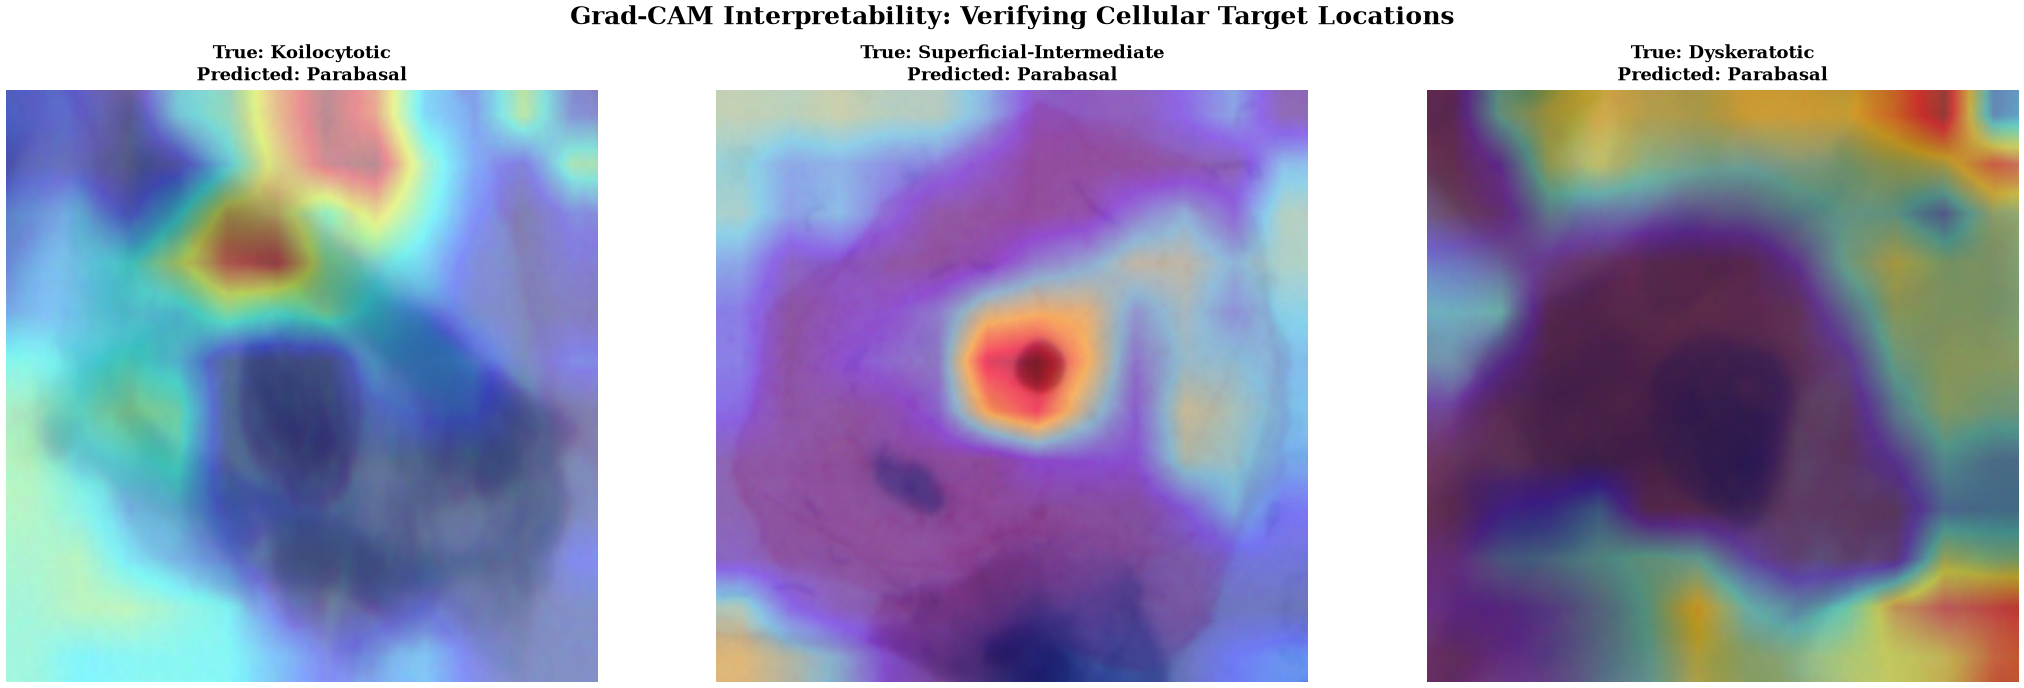

✅ Visualizations securely generated.


In [33]:
# STEP 9 Part 2 — Running Grad-CAM on the Grafted Model
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("⏳ Tracing clinical gradients and painting heatmaps...")

def get_gradcam_heatmap(model, img_array, last_conv_layer_name, pred_index=None):
    backbone = model.get_layer("efficientnetb4")
    # Sub-model mapping the backbone input to its final convolutional layer
    grad_model = tf.keras.models.Model(
        [backbone.inputs], [backbone.get_layer(last_conv_layer_name).output]
    )

    with tf.GradientTape() as tape:
        # Preprocess raw image arrays for the EfficientNet backbone
        x = keras.applications.efficientnet.preprocess_input(img_array)
        conv_outputs = grad_model(x)

        # Trace features through the custom classification head
        pooling_out = model.get_layer("global_average_pooling2d")(conv_outputs)
        batch_norm_out = model.get_layer("batch_normalization")(pooling_out)
        dense_out = model.get_layer("dense")(batch_norm_out)
        dropout_out = model.get_layer("dropout")(dense_out)
        preds = model.get_layer("pred")(dropout_out)

        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Gradients of the class score w.r.t. the feature map
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # ReLU + normalise to [0, 1]
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy(), int(pred_index)

# Output folder (reuses FIGDIR from the figure-styling cell if it ran)
FIGDIR = globals().get("FIGDIR", "figures")
os.makedirs(FIGDIR, exist_ok=True)

plt.figure(figsize=(18, 6))

# One batch of images from the validation set
for images, labels in val_ds.take(1):
    for i in range(3):
        img_single = images[i:i+1]

        # Grad-CAM from the top convolutional layer of EfficientNet-B4
        heatmap, pred_idx = get_gradcam_heatmap(teacher_model_gpu, img_single, "top_conv")

        # Upscale and colourise (OpenCV gives BGR -> convert to RGB for matplotlib)
        heatmap_resized = cv2.resize(heatmap, (380, 380))
        heatmap_scaled = np.uint8(255 * heatmap_resized)
        heatmap_cmap = cv2.applyColorMap(heatmap_scaled, cv2.COLORMAP_JET)
        heatmap_cmap = cv2.cvtColor(heatmap_cmap, cv2.COLOR_BGR2RGB)

        original_img = images[i].numpy().astype("uint8")
        superimposed_img = cv2.addWeighted(heatmap_cmap, 0.4, original_img, 0.6, 0)

        true_name = CLEAN_CLASSES[int(labels[i])]
        pred_name = CLEAN_CLASSES[pred_idx]

        plt.subplot(1, 3, i + 1)
        plt.imshow(superimposed_img)
        plt.title(f"True: {true_name}\nPredicted: {pred_name}", fontsize=11)
        plt.axis("off")

plt.suptitle("Grad-CAM Interpretability: Verifying Cellular Target Locations",
             fontsize=15, weight="bold")
plt.tight_layout()

# Export to disk (PNG for preview, PDF for the paper)
plt.savefig(os.path.join(FIGDIR, "teacher_gradcam.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(FIGDIR, "teacher_gradcam.pdf"), bbox_inches="tight")
print(f"   ↳ saved {FIGDIR}/teacher_gradcam.png and .pdf")

plt.show()
print("✅ Visualizations securely generated.")


# Phase 3: Knowledge Distillation (Step 10)

[Note: We will instantiate a lightweight student model (EfficientNet-B0) and force it to learn from the soft probability outputs of your 97.11% accurate Teacher. This allows the small model to achieve high accuracy while remaining compact enough for low-resource clinical settings.]

⏳ Step 1: Initializing image data streams from directory...
Found 5015 files belonging to 5 classes.
Using 3511 files for training.
Found 5015 files belonging to 5 classes.
Using 1504 files for validation.
   ↳ Data streams securely mounted (70/20/10 train/val/test).

⏳ Step 2: Isolating raw clinical weights from teacher bundle...
   ↳ Raw weights isolated: distill_teacher_weights.h5

⏳ Step 3: Initializing 2-GPU Mirrored Strategy...
🔄 Reconstructing architectures inside distributed scope...
   ↳ 97.11% Teacher model securely grafted onto 2 GPUs.
16705208/16705208 [==============================] - 6s 0us/step
   ↳ Lightweight EfficientNet-B0 Student initialized.
✅ Distillation architecture compiled successfully.

🚀 Step 4: Launching Knowledge Distillation Training across 2 GPUs...
Epoch 1/40


E0000 00:00:1790003227.445162  712308 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inSipakMed_Student_B0/efficientnetb0/block2b_drop/dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


439/439 [==============================] - ETA: 0s - accuracy: 0.6508 - student_loss: 0.9422 - distillation_loss: 0.0027
Epoch 1: val_accuracy improved from -inf to 0.85600, saving model to student_sipakmed_distilled.keras


/root/cyto/venv/lib/python3.12/site-packages/tf_keras/src/saving/saving_api.py:227: UserWarning: You are saving a model that has not yet been built. It might not contain any weights yet. Consider building the model first by calling it on some data.
  saving_lib.save_model(model, local_filepath)


439/439 [==============================] - 117s 170ms/step - accuracy: 0.6508 - student_loss: 0.9411 - distillation_loss: 0.0027 - val_accuracy: 0.8560 - val_student_loss: 0.2345
Epoch 2/40
439/439 [==============================] - ETA: 0s - accuracy: 0.8049 - student_loss: 0.5229 - distillation_loss: 0.0037
Epoch 2: val_accuracy improved from 0.85600 to 0.89800, saving model to student_sipakmed_distilled.keras
439/439 [==============================] - 74s 166ms/step - accuracy: 0.8049 - student_loss: 0.5219 - distillation_loss: 0.0037 - val_accuracy: 0.8980 - val_student_loss: 0.5398
Epoch 3/40
439/439 [==============================] - ETA: 0s - accuracy: 0.8468 - student_loss: 0.4046 - distillation_loss: 0.0040
Epoch 3: val_accuracy improved from 0.89800 to 0.92500, saving model to student_sipakmed_distilled.keras
439/439 [==============================] - 73s 165ms/step - accuracy: 0.8468 - student_loss: 0.4047 - distillation_loss: 0.0040 - val_accuracy: 0.9250 - val_student_loss

ValueError: x and y must have same first dimension, but have shapes (0,) and (24,)

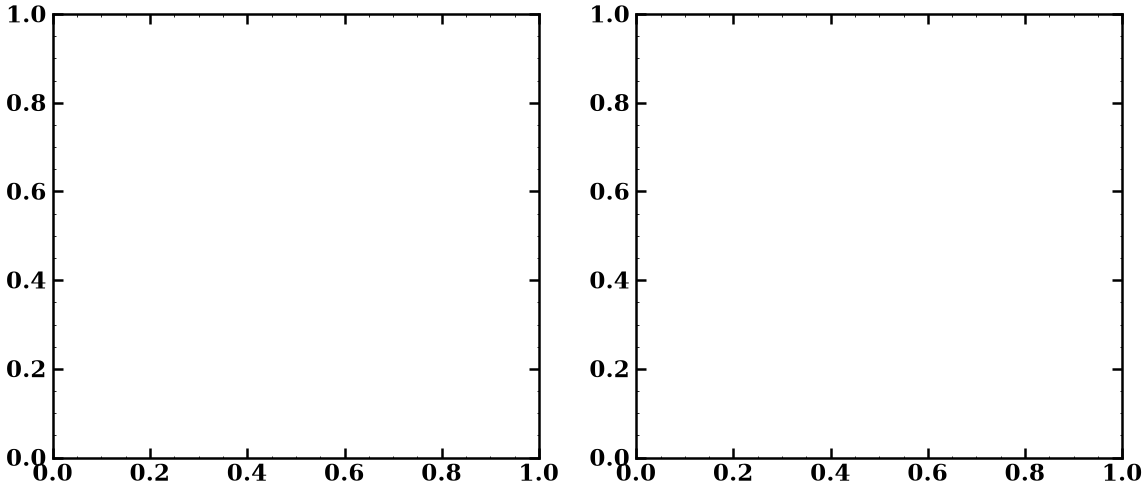

In [34]:
import os
import zipfile
import shutil
import tensorflow as tf

# Force legacy configuration parsing
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tf_keras as keras
from tf_keras import layers

print("⏳ Step 1: Initializing image data streams from directory...")
DATA_ROOT = None
for _cand in [os.environ.get("SIPAKMED_ROOT", ""),
              "/mnt/e/Cervaical Cancer/data/sipakmed",
              "/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed"]:
    if _cand and os.path.isdir(_cand):
        DATA_ROOT = _cand; break
if DATA_ROOT is None:
    DATA_ROOT = "/mnt/e/Cervaical Cancer/data/sipakmed"  # local default (may not exist yet)
SEED = 42
IMG_SIZE = (380, 380)
BATCH_SIZE = 8

# 70/20/10 train/validation/test split (Keras only does 2-way, so hold out 30% and cut it 2:1)
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    DATA_ROOT, validation_split=0.3, subset="training",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='int'
)
holdout_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_ROOT, validation_split=0.3, subset="validation",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='int'
)
# split the 30% holdout into validation (20%) and test (10%)
_hb = tf.data.experimental.cardinality(holdout_ds).numpy()
_vb = int(round(_hb * 2 / 3))
val_ds_raw = holdout_ds.take(_vb)
test_ds_raw = holdout_ds.skip(_vb)

train_ds = train_ds_raw.prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds_raw.prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds_raw.prefetch(buffer_size=tf.data.AUTOTUNE)
print("   ↳ Data streams securely mounted (70/20/10 train/val/test).")

print("\n⏳ Step 2: Isolating raw clinical weights from teacher bundle...")
original_model_path = "teacher_sipakmed_final.keras"
if not os.path.exists(original_model_path):
    original_model_path = "teacher_sipakmed_fixed.keras"

weight_file_temp = "distill_teacher_weights.h5"
with zipfile.ZipFile(original_model_path, "r") as z:
    with z.open("model.weights.h5") as source, open(weight_file_temp, "wb") as target:
        shutil.copyfileobj(source, target)
print(f"   ↳ Raw weights isolated: {weight_file_temp}")

# Structural Replications
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
    layers.GaussianNoise(0.05),
])

def build_teacher_shell(img_shape, num_classes):
    base_model = keras.applications.EfficientNetB4(include_top=False, weights="imagenet", input_shape=img_shape)
    inputs = layers.Input(shape=img_shape, name="input_2")
    x = data_augmentation(inputs, training=False)
    x = keras.applications.efficientnet.preprocess_input(x)
    x = base_model(x)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling2d")(x)
    x = layers.BatchNormalization(name="batch_normalization")(x)
    x = layers.Dense(512, activation="relu", name="dense")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="pred")(x)
    return keras.Model(inputs=inputs, outputs=outputs, name="SipakMed_Teacher_B4_Shell")

# 4. Updated Distiller Framework with Multi-GPU Safe Reductions
class Distiller(keras.Model):
    def __init__(self, student, teacher):
        super().__init__()
        self.teacher = teacher
        self.student = student

    def compile(self, optimizer, metrics, student_loss_fn, distillation_loss_fn, alpha=0.1, temperature=3.0):
        super().compile(optimizer=optimizer, metrics=metrics)
        self.student_loss_fn = student_loss_fn
        self.distillation_loss_fn = distillation_loss_fn
        self.alpha = alpha
        self.temperature = temperature

    def train_step(self, data):
        x, y = data
        teacher_predictions = self.teacher(x, training=False)

        with tf.GradientTape() as tape:
            student_predictions = self.student(x, training=True)
            
            # 1. Compute raw, unreduced per-example losses
            student_loss_per_example = self.student_loss_fn(y, student_predictions)
            distillation_loss_per_example = self.distillation_loss_fn(
                tf.nn.softmax(teacher_predictions / self.temperature, axis=-1),
                tf.nn.softmax(student_predictions / self.temperature, axis=-1)
            )
            
            # 2. Safely average losses across the global distributed batch size
            student_loss = tf.nn.compute_average_loss(student_loss_per_example)
            distillation_loss = tf.nn.compute_average_loss(distillation_loss_per_example)
            
            # 3. Blend total weighted loss
            loss = self.alpha * student_loss + (1.0 - self.alpha) * distillation_loss

        trainable_vars = self.student.trainable_variables
        gradients = tape.gradient(loss, trainable_vars)
        self.optimizer.apply_gradients(zip(gradients, trainable_vars))

        self.compiled_metrics.update_state(y, student_predictions)
        results = {m.name: m.result() for m in self.metrics}
        results.update({"student_loss": student_loss, "distillation_loss": distillation_loss})
        return results

    def test_step(self, data):
        x, y = data
        preds = self.student(x, training=False)
        
        # Apply identical global scale reductions during the validation pass
        student_loss_per_example = self.student_loss_fn(y, preds)
        student_loss = tf.nn.compute_average_loss(student_loss_per_example)
        
        self.compiled_metrics.update_state(y, preds)
        results = {m.name: m.result() for m in self.metrics}
        results.update({"student_loss": student_loss})
        return results

print("\n⏳ Step 3: Initializing 2-GPU Mirrored Strategy...")
_gpus_d = tf.config.list_physical_devices('GPU')
strategy = tf.distribute.MirroredStrategy() if len(_gpus_d) > 1 else tf.distribute.get_strategy()

with strategy.scope():
    print("🔄 Reconstructing architectures inside distributed scope...")
    
    # Instantiate and graft weights onto Teacher shell
    teacher_model_distill = build_teacher_shell((380, 380, 3), num_classes=5)
    teacher_model_distill.load_weights(weight_file_temp, by_name=True)
    teacher_model_distill.trainable = False
    print("   ↳ 97.11% Teacher model securely grafted onto 2 GPUs.")
    
    # Build a completely fresh EfficientNet-B0 Student model
    student_backbone = keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet", input_shape=(380, 380, 3)
    )
    student_backbone.trainable = True
    
    student_inputs = layers.Input(shape=(380, 380, 3), name="student_input")
    x = student_backbone(student_inputs)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    student_outputs = layers.Dense(5, activation="softmax")(x)
    base_student = keras.Model(inputs=student_inputs, outputs=student_outputs, name="SipakMed_Student_B0")
    print("   ↳ Lightweight EfficientNet-B0 Student initialized.")

    # Explicitly set reduction=NONE to handle custom multi-GPU step scaling safely
    distiller_model = Distiller(student=base_student, teacher=teacher_model_distill)
    distiller_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=5e-5),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
        student_loss_fn=keras.losses.SparseCategoricalCrossentropy(reduction=keras.losses.Reduction.NONE),
        distillation_loss_fn=keras.losses.KLDivergence(reduction=keras.losses.Reduction.NONE),
        alpha=0.1,        
        temperature=4.0   
    )
    print("✅ Distillation architecture compiled successfully.")

# Clean up temp h5 file from disk
if os.path.exists(weight_file_temp):
    os.remove(weight_file_temp)

print("\n🚀 Step 4: Launching Knowledge Distillation Training across 2 GPUs...")
callbacks_student = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint("student_sipakmed_distilled.keras", monitor="val_accuracy", save_best_only=True, verbose=1)
]

history_distill = distiller_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_student
)
print("✅ Knowledge Distillation Complete!")

# ---- Final held-out TEST evaluation of the distilled student ----
import numpy as np
from sklearn.metrics import classification_report
print("\n📊 Student evaluation on the held-out TEST set (10%):")
y_true_t, y_pred_t = [], []
for images, labels in test_ds:
    p = base_student.predict(images, verbose=0)
    y_true_t.extend(labels.numpy()); y_pred_t.extend(np.argmax(p, axis=1))
print(classification_report(y_true_t, y_pred_t,
      target_names=['Dyskeratotic','Koilocytotic','Metaplastic','Parabasal','Superficial-Intermediate']))
print(f"✅ Student Test Accuracy: {np.mean(np.array(y_true_t)==np.array(y_pred_t)):.4f}")

# ---- Publication figures for the distilled STUDENT (training curve + held-out test eval) ----
plot_training_curves(history_distill, "student_training",
                     title="Student (EfficientNet-B0) distillation training")

_student_labels = ['Dyskeratotic', 'Koilocytotic', 'Metaplastic', 'Parabasal', 'Superficial-Intermediate']
sy_true, sy_pred, sy_score = [], [], []
for images, labels in test_ds:
    p = base_student.predict(images, verbose=0)
    sy_true.extend(labels.numpy()); sy_pred.extend(np.argmax(p, axis=1)); sy_score.extend(p)
sy_true, sy_pred, sy_score = np.array(sy_true), np.array(sy_pred), np.array(sy_score)

plot_confusion(sy_true, sy_pred, _student_labels, "student_confusion",
               title="Student confusion matrix (held-out test)")
plot_roc(sy_true, sy_score, _student_labels, "student_roc",
         title="Student ROC (held-out test, one-vs-rest)")
plot_classification_report(sy_true, sy_pred, _student_labels, "student_classification_report",
                           title="Student classification report (held-out test)")


   ↳ saved figures/student_training.pdf  and  figures/student_training.png


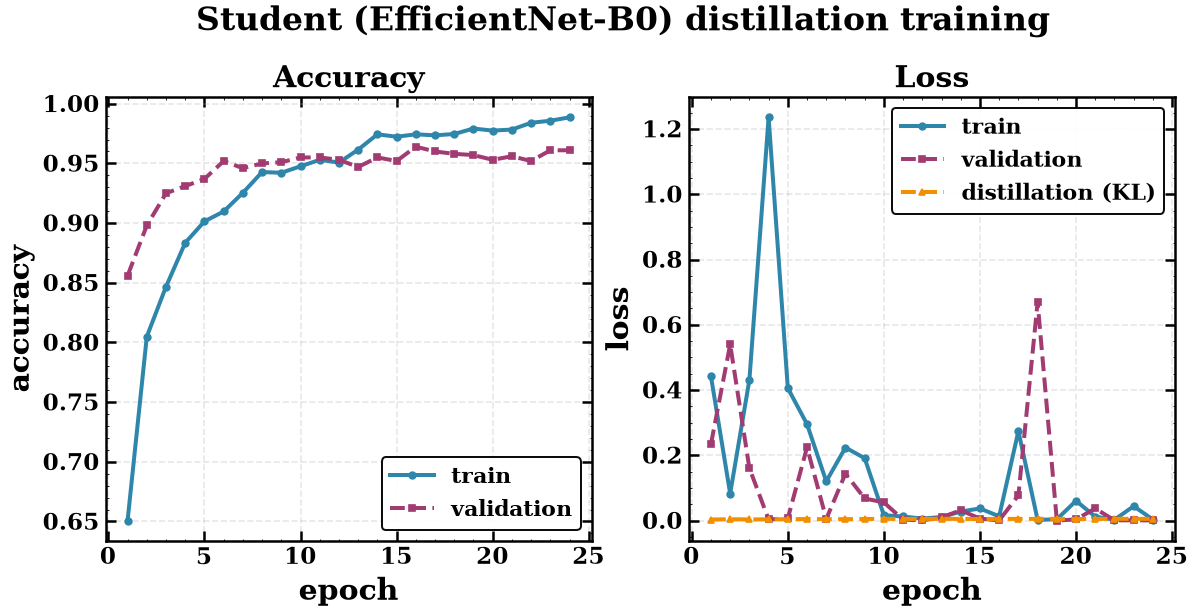

   ↳ saved figures/student_confusion.pdf  and  figures/student_confusion.png


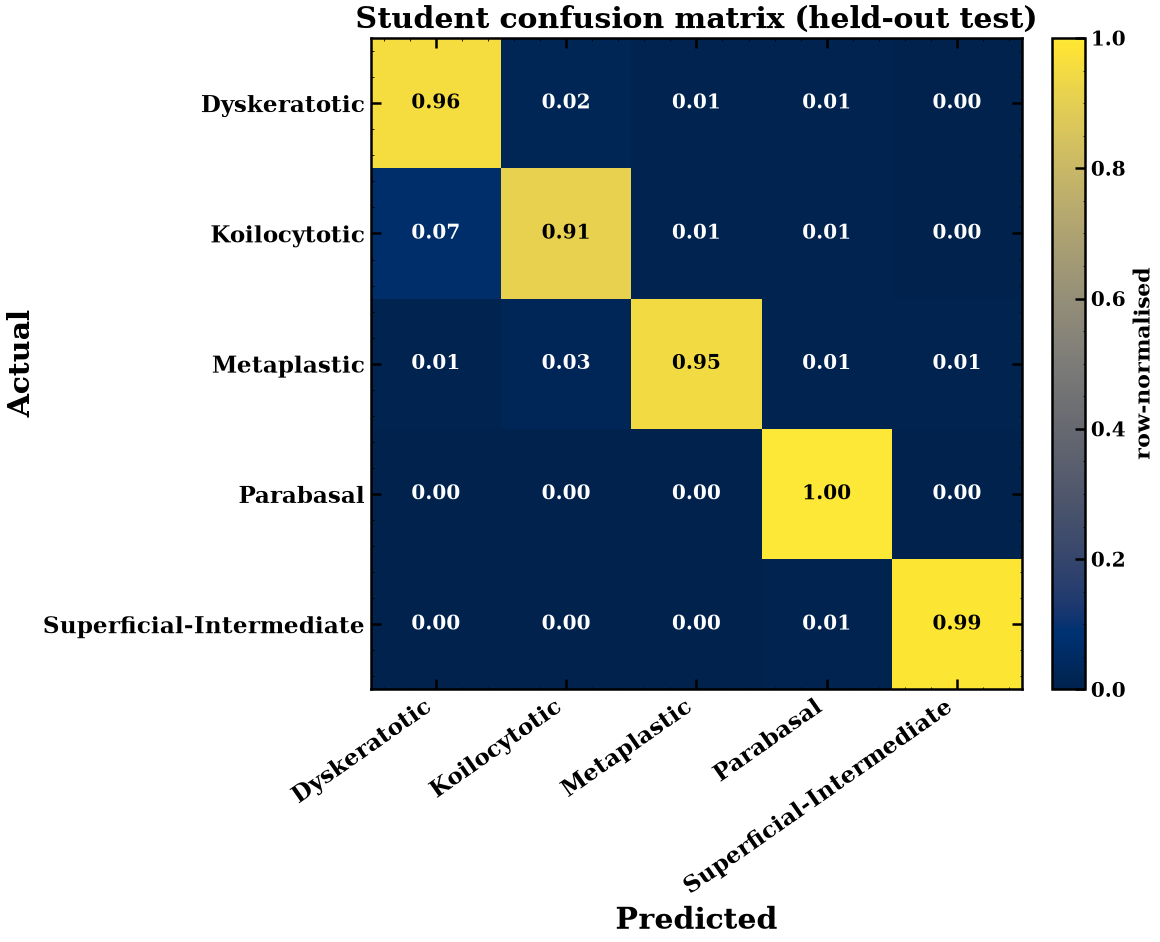

   ↳ saved figures/student_roc.pdf  and  figures/student_roc.png


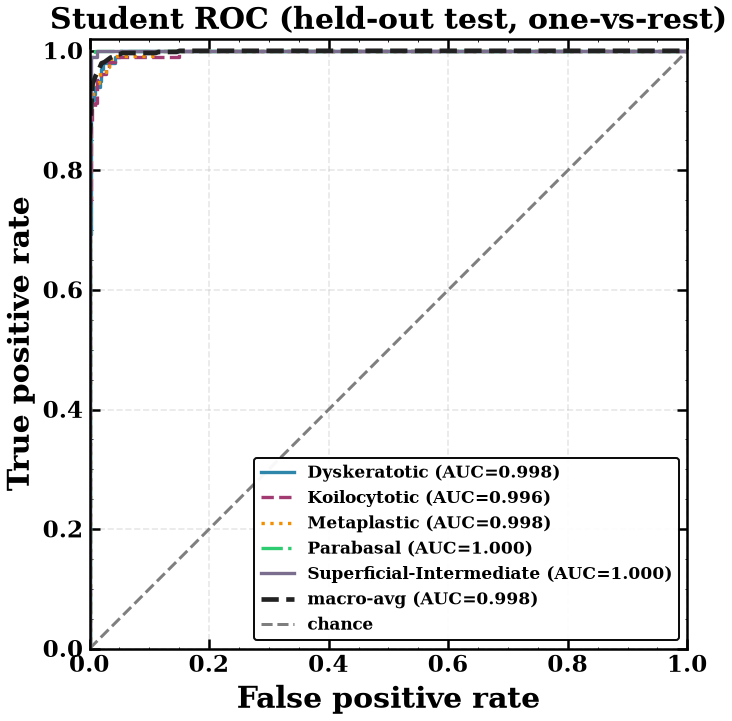

   ↳ saved figures/student_classification_report.pdf  and  figures/student_classification_report.png


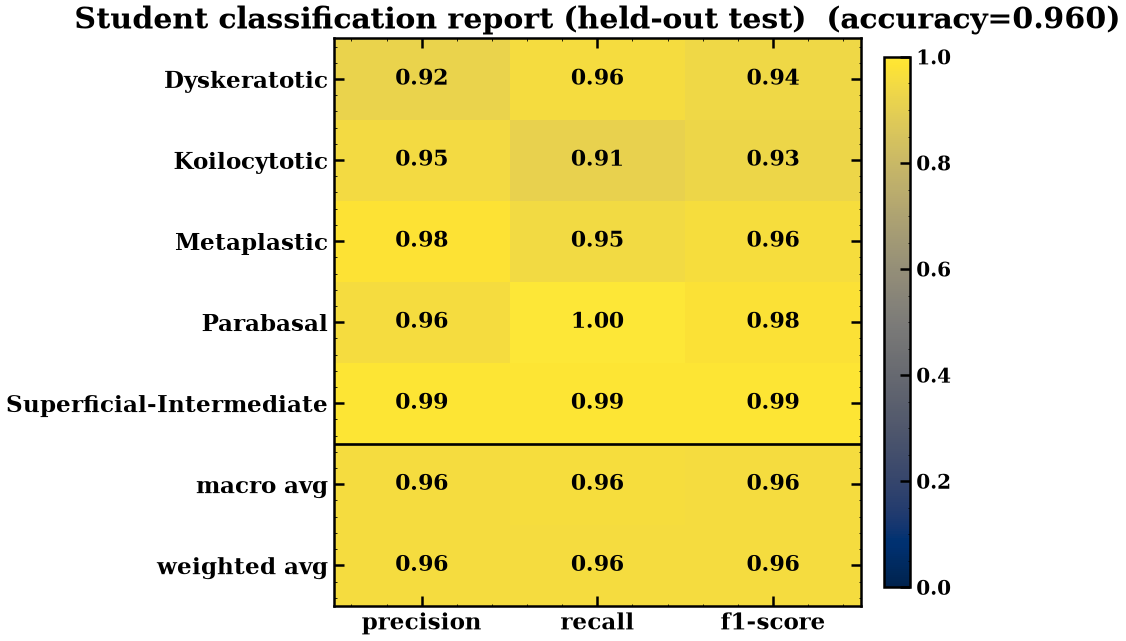

'figures/student_classification_report.png'

In [35]:
# Student publication figures — run this instead of re-running the distillation cell
import numpy as np

def plot_training_curves(history, stem, title="Training curves"):
    h = history.history if hasattr(history, "history") else history
    # model.fit() logs "loss"/"val_loss"; the custom Distiller logs "student_loss"/"val_student_loss"
    tr_loss = next((k for k in ("loss", "student_loss") if k in h), None)
    va_loss = next((k for k in ("val_loss", "val_student_loss") if k in h), None)
    ep = lambda v: np.arange(1, len(v) + 1)

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.8))
    if "accuracy" in h:
        a1.plot(ep(h["accuracy"]), h["accuracy"], color=color("train"), marker="o", ms=4, label="train")
    if "val_accuracy" in h:
        a1.plot(ep(h["val_accuracy"]), h["val_accuracy"], color=color("val"), marker="s", ms=4, label="validation")
    a1.set_xlabel("epoch"); a1.set_ylabel("accuracy"); a1.set_title("Accuracy")
    a1.legend(loc="lower right"); a1.grid(True, alpha=0.3, linestyle="--"); a1.set_axisbelow(True)

    if tr_loss:
        a2.plot(ep(h[tr_loss]), h[tr_loss], color=color("train"), marker="o", ms=4, label="train")
    if va_loss:
        a2.plot(ep(h[va_loss]), h[va_loss], color=color("val"), marker="s", ms=4, label="validation")
    if "distillation_loss" in h:
        a2.plot(ep(h["distillation_loss"]), h["distillation_loss"], color=color("test"),
                linestyle="--", marker="^", ms=4, label="distillation (KL)")
    a2.set_xlabel("epoch"); a2.set_ylabel("loss"); a2.set_title("Loss")
    a2.legend(loc="upper right"); a2.grid(True, alpha=0.3, linestyle="--"); a2.set_axisbelow(True)

    fig.suptitle(title, fontweight="bold", y=1.04)
    return save(fig, stem)

# ---- Student figures: training curve + held-out test evaluation ----
plot_training_curves(history_distill, "student_training",
                     title="Student (EfficientNet-B0) distillation training")

_student_labels = ['Dyskeratotic', 'Koilocytotic', 'Metaplastic', 'Parabasal', 'Superficial-Intermediate']
sy_true, sy_pred, sy_score = [], [], []
for images, labels in test_ds:
    p = base_student.predict(images, verbose=0)
    sy_true.extend(labels.numpy()); sy_pred.extend(np.argmax(p, axis=1)); sy_score.extend(p)
sy_true, sy_pred, sy_score = np.array(sy_true), np.array(sy_pred), np.array(sy_score)

plot_confusion(sy_true, sy_pred, _student_labels, "student_confusion",
               title="Student confusion matrix (held-out test)")
plot_roc(sy_true, sy_score, _student_labels, "student_roc",
         title="Student ROC (held-out test, one-vs-rest)")
plot_classification_report(sy_true, sy_pred, _student_labels, "student_classification_report",
                           title="Student classification report (held-out test)")


In [36]:
# RUN THIS ONLY AFTER TRAINING COMPLETES
# Directly secures the actual trained EfficientNet-B0 brain
base_student.save("student_sipakmed_final_distilled.keras")
print("🎉 SUCCESS: Lightweight student model weights permanently secured!")

🎉 SUCCESS: Lightweight student model weights permanently secured!
